# **Bài 1**

In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# 1. Tải dữ liệu và chia tập train/test
data = load_breast_cancer()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 2. Chuẩn hóa dữ liệu đầu vào
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Thực nghiệm với các kernel khác nhau
kernels = ['linear', 'rbf', 'poly', 'sigmoid']
results = []

for kernel in kernels:
    model = SVC(kernel=kernel, C=1.0, gamma='scale', random_state=42)
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    results.append({
        'Kernel': kernel,
        'Accuracy': round(acc, 4)
    })

    print(f"=== Kernel: {kernel} (Accuracy: {acc:.4f}) ===")
    print(classification_report(y_test, y_pred, target_names=data.target_names, digits=4))

df_kernels = pd.DataFrame(results).sort_values(by='Accuracy', ascending=False)
print("Bảng xếp hạng hiệu suất theo kernel:")
print(df_kernels.to_string(index=False))

=== Kernel: linear (Accuracy: 0.9737) ===
              precision    recall  f1-score   support

   malignant     0.9535    0.9762    0.9647        42
      benign     0.9859    0.9722    0.9790        72

    accuracy                         0.9737       114
   macro avg     0.9697    0.9742    0.9719       114
weighted avg     0.9740    0.9737    0.9737       114

=== Kernel: rbf (Accuracy: 0.9825) ===
              precision    recall  f1-score   support

   malignant     0.9762    0.9762    0.9762        42
      benign     0.9861    0.9861    0.9861        72

    accuracy                         0.9825       114
   macro avg     0.9812    0.9812    0.9812       114
weighted avg     0.9825    0.9825    0.9825       114

=== Kernel: poly (Accuracy: 0.9123) ===
              precision    recall  f1-score   support

   malignant     1.0000    0.7619    0.8649        42
      benign     0.8780    1.0000    0.9351        72

    accuracy                         0.9123       114
   macr

# **Bài 2**

In [2]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Tải dữ liệu, chia tập train/test và chuẩn hóa
data = load_breast_cancer()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 2. Khai báo lưới siêu tham số cần tìm kiếm
param_grid = [
    {'kernel': ['linear'], 'C': [0.1, 1, 10, 100]},
    {'kernel': ['rbf'], 'C': [0.1, 1, 10, 100], 'gamma': ['scale', 'auto', 0.01, 0.001]},
    {'kernel': ['poly'], 'C': [0.1, 1, 10], 'degree': [2, 3], 'gamma': ['scale', 'auto']}
]

# 3. Khởi tạo và chạy GridSearchCV (cv=5)
grid_search = GridSearchCV(
    estimator=SVC(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
grid_search.fit(X_train_scaled, y_train)

print("Bộ siêu tham số tối ưu:", grid_search.best_params_)
print(f"Điểm trung bình CV tốt nhất: {grid_search.best_score_:.4f}")

# 4. Đánh giá mô hình tốt nhất trên tập kiểm tra
best_svm = grid_search.best_estimator_
y_pred = best_svm.predict(X_test_scaled)
test_acc = accuracy_score(y_test, y_pred)

print(f"Độ chính xác trên tập test: {test_acc:.4f}")
print("\nMa trận nhầm lẫn:")
print(confusion_matrix(y_test, y_pred))
print("\nBáo cáo phân loại:")
print(classification_report(y_test, y_pred, target_names=data.target_names, digits=4))

Bộ siêu tham số tối ưu: {'C': 0.1, 'kernel': 'linear'}
Điểm trung bình CV tốt nhất: 0.9802
Độ chính xác trên tập test: 0.9825

Ma trận nhầm lẫn:
[[41  1]
 [ 1 71]]

Báo cáo phân loại:
              precision    recall  f1-score   support

   malignant     0.9762    0.9762    0.9762        42
      benign     0.9861    0.9861    0.9861        72

    accuracy                         0.9825       114
   macro avg     0.9812    0.9812    0.9812       114
weighted avg     0.9825    0.9825    0.9825       114



# **Bài 3**

=== KNN (K=5) | Accuracy: 0.9639 ===
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        36
           1     0.9231    1.0000    0.9600        36
           2     0.9459    1.0000    0.9722        35
           3     1.0000    0.9730    0.9863        37
           4     0.9714    0.9444    0.9577        36
           5     0.9730    0.9730    0.9730        37
           6     0.9730    1.0000    0.9863        36
           7     0.9211    0.9722    0.9459        36
           8     0.9688    0.8857    0.9254        35
           9     0.9697    0.8889    0.9275        36

    accuracy                         0.9639       360
   macro avg     0.9646    0.9637    0.9634       360
weighted avg     0.9648    0.9639    0.9636       360

=== SVM (kernel='poly') | Accuracy: 0.9722 ===
              precision    recall  f1-score   support

           0     1.0000    0.9722    0.9859        36
           1     0.9722    0.9722    0.9722     

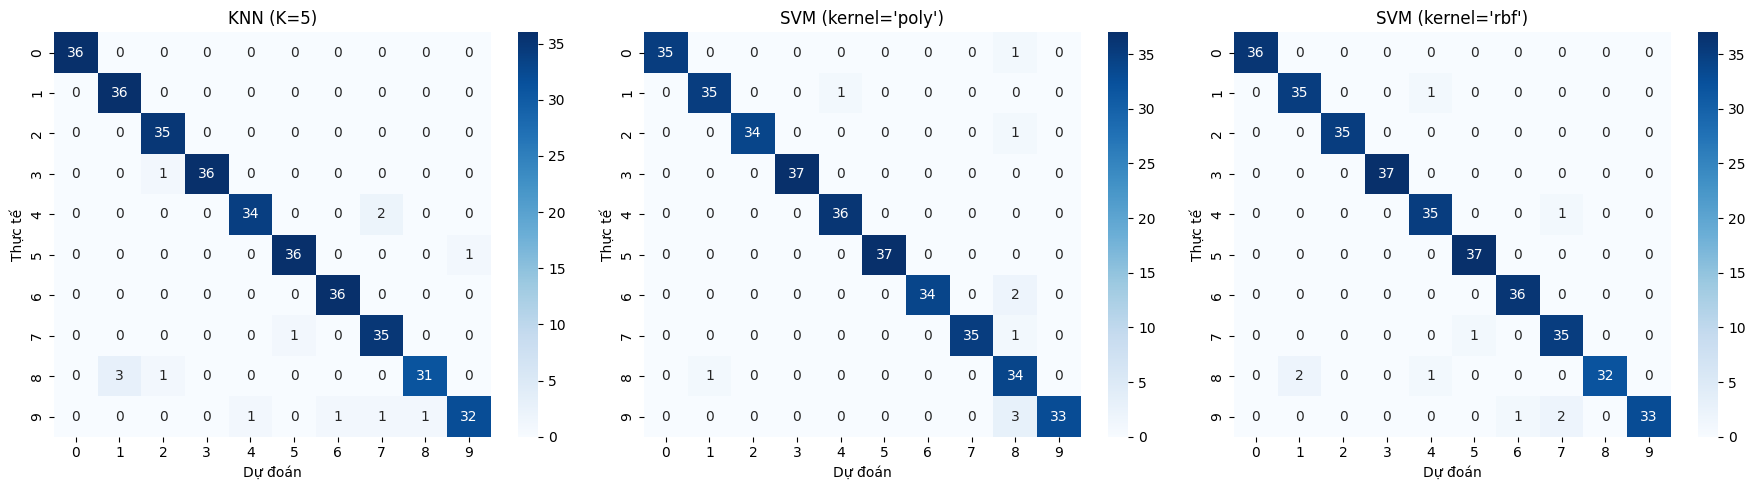

In [3]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Tải tập dữ liệu Digits từ sklearn.datasets
digits = load_digits()
X, y = digits.data, digits.target
class_names = [str(i) for i in digits.target_names]

# 2. Chuẩn hóa dữ liệu và phân chia thành tập huấn luyện và tập kiểm tra
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Huấn luyện lần lượt KNN, SVM (poly) và SVM (rbf)
models = {
    "KNN (K=5)": KNeighborsClassifier(n_neighbors=5),
    "SVM (kernel='poly')": SVC(kernel='poly', degree=3, C=1.0, gamma='scale', random_state=42),
    "SVM (kernel='rbf')": SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
}

acc_summary = []
conf_matrices = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    acc_summary.append({'Mô hình': name, 'Accuracy': round(acc, 4)})
    conf_matrices[name] = confusion_matrix(y_test, y_pred)

    print(f"=== {name} | Accuracy: {acc:.4f} ===")
    print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

# 4. So sánh độ chính xác và hiển thị ma trận nhầm lẫn
df_acc = pd.DataFrame(acc_summary).sort_values(by='Accuracy', ascending=False)
print("Bảng so sánh độ chính xác trên tập dữ liệu Digits:")
print(df_acc.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, cm) in zip(axes, conf_matrices.items()):
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=class_names, yticklabels=class_names, ax=ax
    )
    ax.set_title(name)
    ax.set_xlabel("Dự đoán")
    ax.set_ylabel("Thực tế")

plt.tight_layout()
plt.show()